In [77]:
import matplotlib.pyplot as plt
import numpy as np
import scipy
import scipy.stats
from scipy.stats import norm

In [78]:
%load_ext autoreload
%autoreload 2
from src.Brownian_motion import brownian_motion, simulate_brownian_paths, simulate_brownian_ruin, run_for_n, estimate_brownian_ruin


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


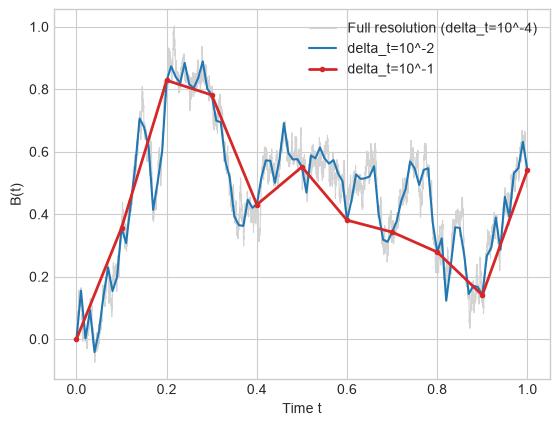

In [79]:
B, t = brownian_motion(10000, 1)

B_100 = B[0::100]
t_100 = t[0::100]

B_1000 = B[0::1000]
t_1000 = t[0::1000]

plt.plot(t, B, color="lightgray", linewidth=0.8, zorder=1, label="Full resolution (delta_t=10^-4)")
plt.plot(t_100, B_100, color="#1f77b4", linewidth=1.5, zorder=2, label="delta_t=10^-2")
plt.plot(t_1000, B_1000, color="#d62728", linewidth=2, marker='o', markersize=3, zorder=3, label="delta_t=10^-1")
plt.xlabel("Time t")
plt.ylabel("B(t)")
plt.legend()

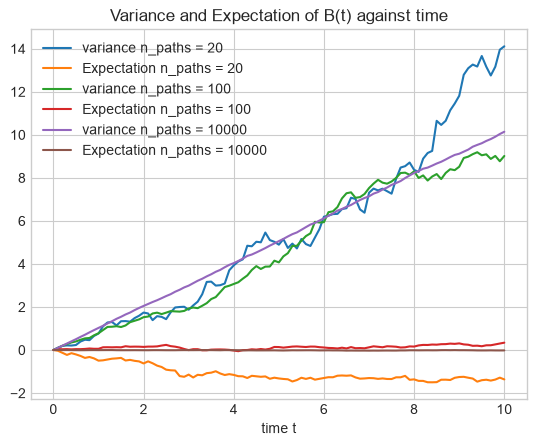

In [80]:
n_paths = [20,100,10000]
for i in n_paths:
    B, t = simulate_brownian_paths(i, 100, 10)

#for i in range(0, len(B)):
#    plt.plot(t, B[i,:])
    var_B = np.var(B, axis=0)
    exp_B = np.mean(B, axis=0)

    plt.plot(t, var_B, label=f"variance n_paths = {i}")
    plt.plot(t, exp_B, label=f"Expectation n_paths = {i}")

plt.xlabel("time t")
plt.title("Variance and Expectation of B(t) against time")
plt.legend()


[9.99 6.66 3.33]
[999]
[666]
[333]


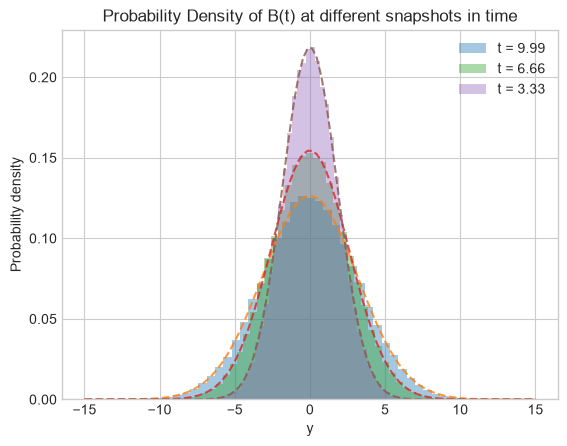

In [81]:
n_paths = 100000
n_steps = 1000
sigma = 1
B, t = simulate_brownian_paths(n_paths, n_steps, 10, sigma=1)
y = np.linspace(-15, 15, 100)

times = t[0::int(n_steps/3)]
times = np.flip(times[1:])
print(times)
for i in times:
    idx = np.argwhere(t == i).reshape(-1)
    print(idx)
    plt.hist(B[:, idx], bins=50, density=True, alpha=0.4, label=f"t = {i}")
    pdf = norm.pdf(y, loc=0, scale=sigma*np.sqrt(i))
    plt.plot(y, pdf, '--', alpha=0.8)
plt.ylabel("Probability density")
plt.xlabel("y")
plt.title("Probability Density of B(t) at different snapshots in time")
plt.legend()

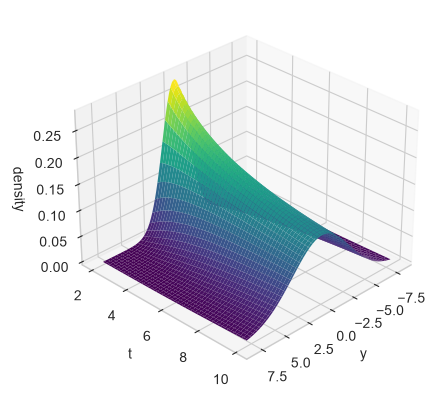

In [82]:
y = np.linspace(-8, 8, 100)

t_grid = np.linspace(2, 10, 100)   # avoid t=0 (density undefined/degenerate)
Y, Tt = np.meshgrid(y, t_grid)
P = norm.pdf(Y, loc=0, scale=sigma*np.sqrt(Tt))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(Y, Tt, P, cmap='viridis')
ax.set_xlabel("y")
ax.set_ylabel("t")
ax.set_zlabel("density")
ax.view_init(elev=30, azim=45)

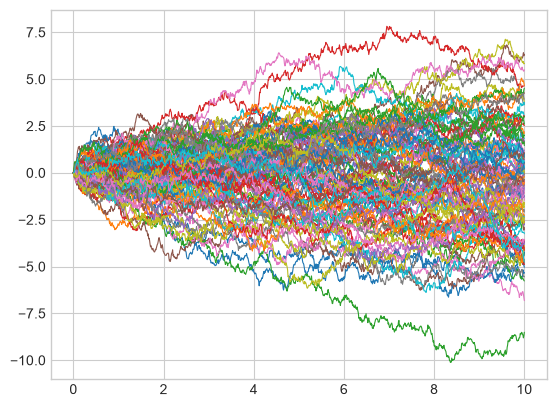

In [83]:
B, t = simulate_brownian_paths(100, 1000, 10)

for i in B:
    plt.plot(t, i, linewidth=0.8, zorder=1, label="Full resolution (delta_t=10^-4)")

Text(0.5, 1.0, 'Gamblers ruin in continuous time with duration T=518.9')

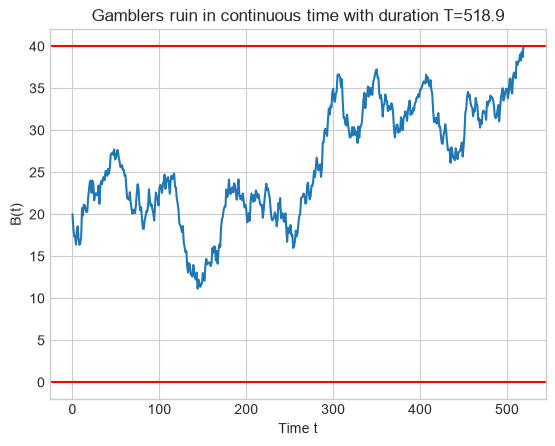

In [84]:
B, final_position, T, t = simulate_brownian_ruin(1, 20, 40)
plt.plot(t, B)
plt.xlabel("Time t")
plt.ylabel("B(t)")
plt.axhline(y=40, color = "red")
plt.axhline(y=0, color = "red")
plt.title(f"Gamblers ruin in continuous time with duration T={round(T, 2)}")

In [85]:
from concurrent.futures import ProcessPoolExecutor

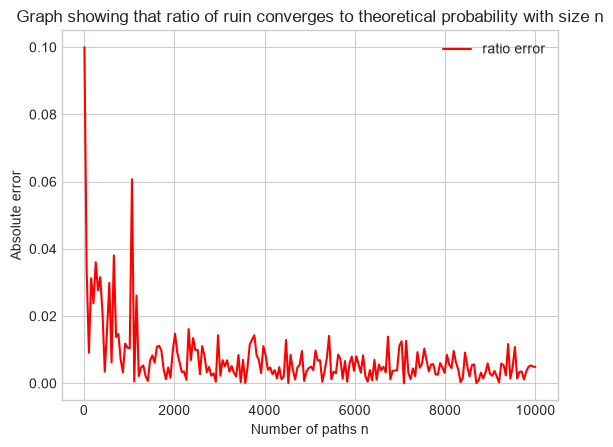

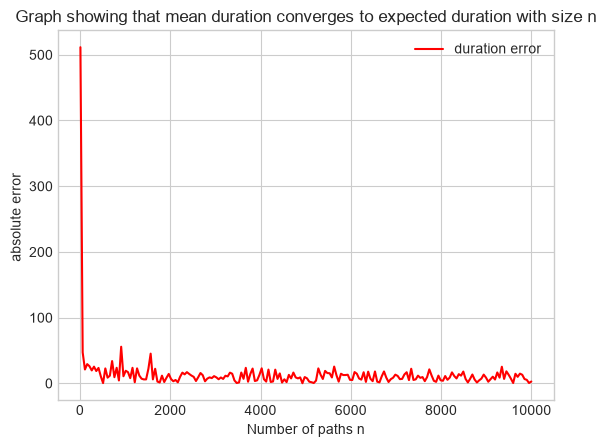

In [86]:
n_paths = np.linspace(10,10000,200).astype(int)

dt = 0.1
a = 20
m = 50
theoretical_prob = (m-a)/m
theoretical_duration = a*(m-a)

args = [(n, dt, a, m) for n in n_paths]

with ProcessPoolExecutor() as executor:
    results = list(executor.map(run_for_n, args))

ratios, durations = zip(*results)
ratios = np.array(ratios)
durations = np.array(durations)

ratio_error = abs(np.array(ratios) - theoretical_prob)
duration_error = abs(np.array(durations) - theoretical_duration)

plt.plot(n_paths, ratio_error, label="ratio error", color="red")
plt.legend()
plt.xlabel("Number of paths n")
plt.ylabel("Absolute error")
plt.title("Graph showing that ratio of ruin converges to theoretical probability with size n")
plt.show()

plt.plot(n_paths, duration_error, label="duration error", color="red")
plt.legend()
plt.xlabel("Number of paths n")
plt.ylabel("absolute error ")
plt.title("Graph showing that mean duration converges to expected duration with size n")
plt.show()

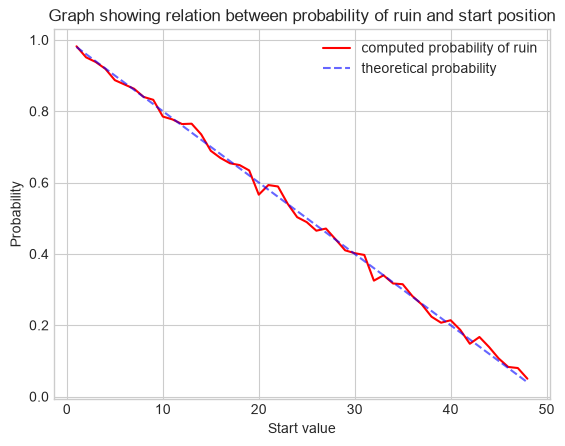

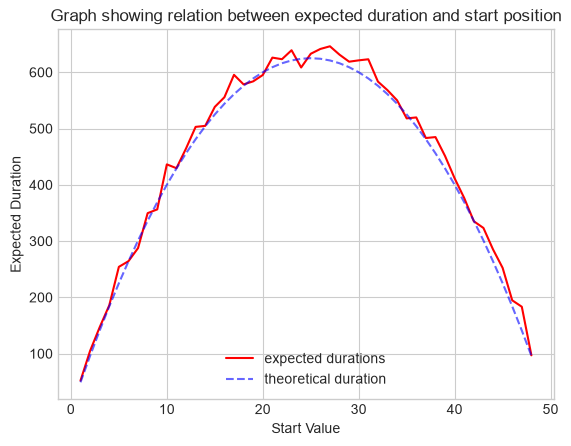

In [87]:
start_values = np.arange(1, 49, 1)

dt = 0.1
m = 50
n = 1000

args = [(n, dt, a, m) for a in start_values]

with ProcessPoolExecutor() as executor:
    results = list(executor.map(run_for_n, args))

ratios, durations = zip(*results)
ratios = np.array(ratios)
durations = np.array(durations)

theoretical_prob = (m-start_values)/m
theoretical_duration = start_values*(m-start_values)

plt.plot(start_values, ratios, label="computed probability of ruin", color="red")
plt.plot(start_values, theoretical_prob,"--", label="theoretical probability", color="blue", alpha=0.6)
plt.legend()
plt.xlabel("Start value")
plt.ylabel("Probability")
plt.title("Graph showing relation between probability of ruin and start position")
plt.show()

plt.plot(start_values, durations, label="expected durations", color="red")
plt.plot(start_values, theoretical_duration,"--", label="theoretical duration", color="blue", alpha=0.6)
plt.legend()
plt.xlabel("Start Value")
plt.ylabel("Expected Duration")
plt.title("Graph showing relation between expected duration and start position")
plt.show()